**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

*   NOMBRE: Yan Carlo Jiménez De La Rosa, José Arnulfo Juárez Figueroa, Gael Isaac Jurado Romero, José Pablo Kiesling Lange
*   EQUIPO: 33

En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [2]:
url = "https://raw.githubusercontent.com/GJ030/Ciencia_datos/main/8.2%20Actividad%208%20-%20Regresi%C3%B3n%20lineal/diamonds_dataset.csv"
diamonds_df = pd.read_csv(url)
diamonds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [3]:
diamonds_df.nunique()

carat        271
cut            5
color          7
clarity        8
depth        184
table        127
x            550
y            549
z            371
price      11595
dtype: int64

In [4]:
diamonds_df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
price      0
dtype: int64

In [5]:
print("Registros duplicados:", diamonds_df.duplicated().sum())
diamonds_df = diamonds_df.drop_duplicates().reset_index(drop=True)
print("Dimensiones tras eliminarlos:", diamonds_df.shape)

Registros duplicados: 145
Dimensiones tras eliminarlos: (53771, 10)


**Respuesta 1**

El dataframe tiene 10 columnas: 7 numéricas (`carat`, `depth`, `table`, `x`, `y`, `z` y `price`) y 3 de texto (`cut`, `color` y `clarity`). No hay valores faltantes en ninguna columna. Había 145 registros duplicados, que se eliminaron, por lo que quedaron 53,771 registros con el índice reiniciado.

2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

In [6]:
num_cols = diamonds_df.select_dtypes(include="number").columns
diamonds_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53771.0,0.797323,0.472474,0.20,0.40,0.70,1.04,4.50
depth,53771.0,61.748160,1.429519,43.00,61.00,61.80,62.50,79.00
table,53771.0,57.457635,2.233192,43.00,56.00,57.00,59.00,95.00
x,53771.0,5.731280,1.118102,3.73,4.71,5.70,6.54,10.23
y,53771.0,5.734618,1.138982,3.68,4.72,5.71,6.54,58.90
z,53771.0,3.539774,0.701677,1.07,2.91,3.53,4.03,31.80
price,53771.0,3930.320545,3984.687429,326.00,951.00,2401.00,5323.50,18823.00


In [7]:
cat_cols = diamonds_df.select_dtypes(exclude="number").columns
diamonds_df[cat_cols].describe().T

,count,unique,top,freq
cut,53771,5,Ideal,21485
color,53771,7,G,11254
clarity,53771,8,SI1,13030


In [8]:
cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["D", "E", "F", "G", "H", "I", "J"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
orders = {"cut": cut_order, "color": color_order, "clarity": clarity_order}

for col in cat_cols:
    print(diamonds_df[col].value_counts().reindex(orders[col]), end="\n\n")

cut
Fair          1596
Good          4888
Very Good    12065
Premium      13737
Ideal        21485
Name: count, dtype: int64

color
D     6753
E     9776
F     9517
G    11254
H     8266
I     5404
J     2801
Name: count, dtype: int64

clarity
I1        735
SI2      9140
SI1     13030
VS2     12225
VS1      8155
VVS2     5056
VVS1     3646
IF       1784
Name: count, dtype: int64



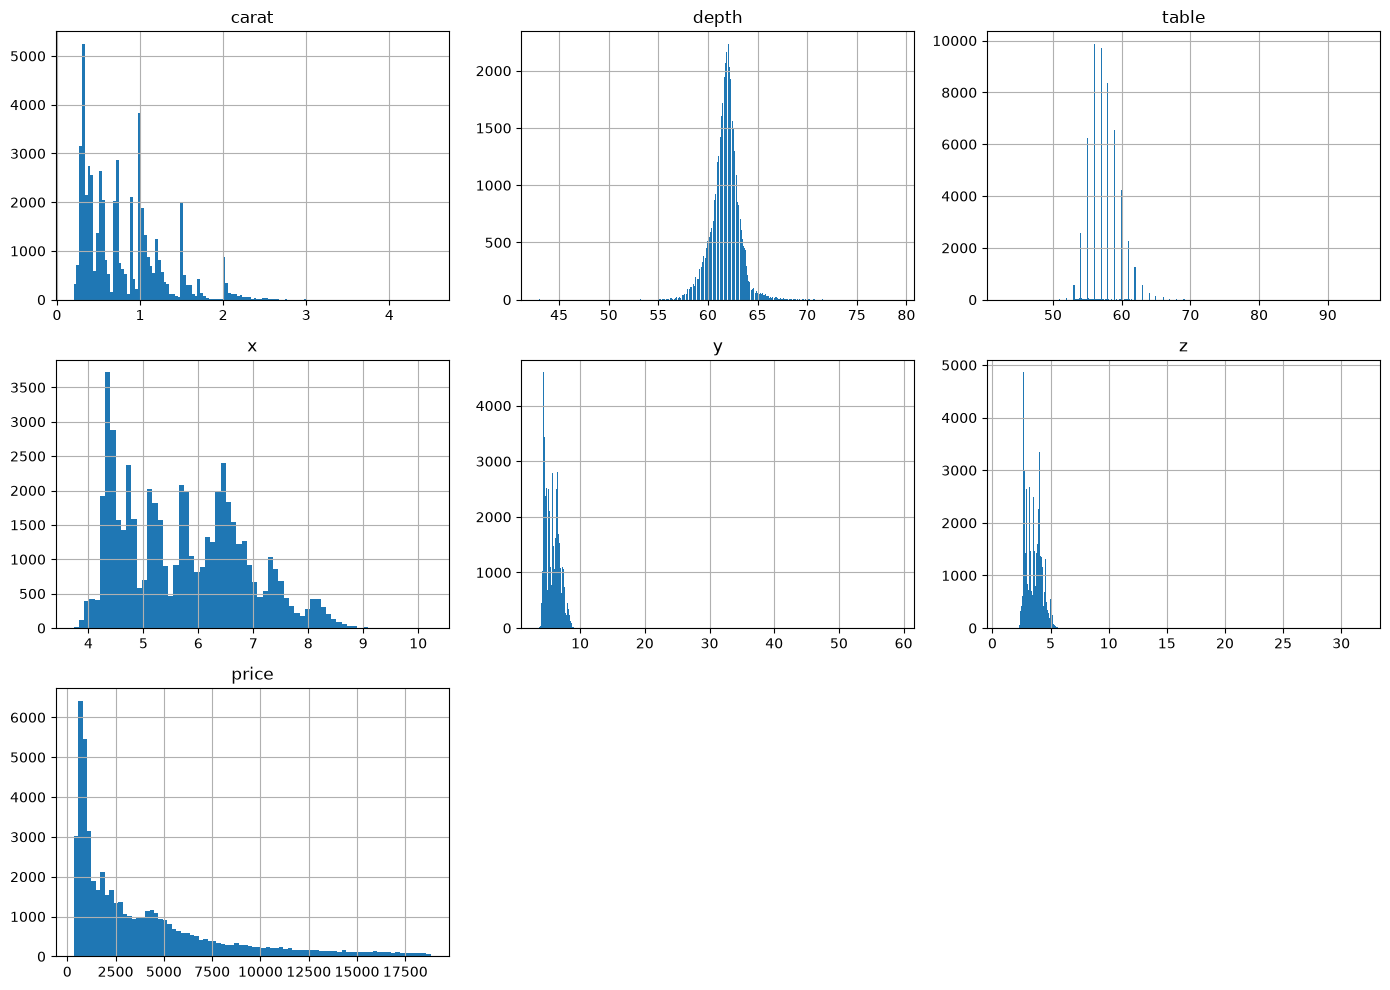

In [9]:
diamonds_df[num_cols].hist(bins="auto", layout=(3, 3), figsize=(14, 10))
plt.tight_layout()
plt.show()

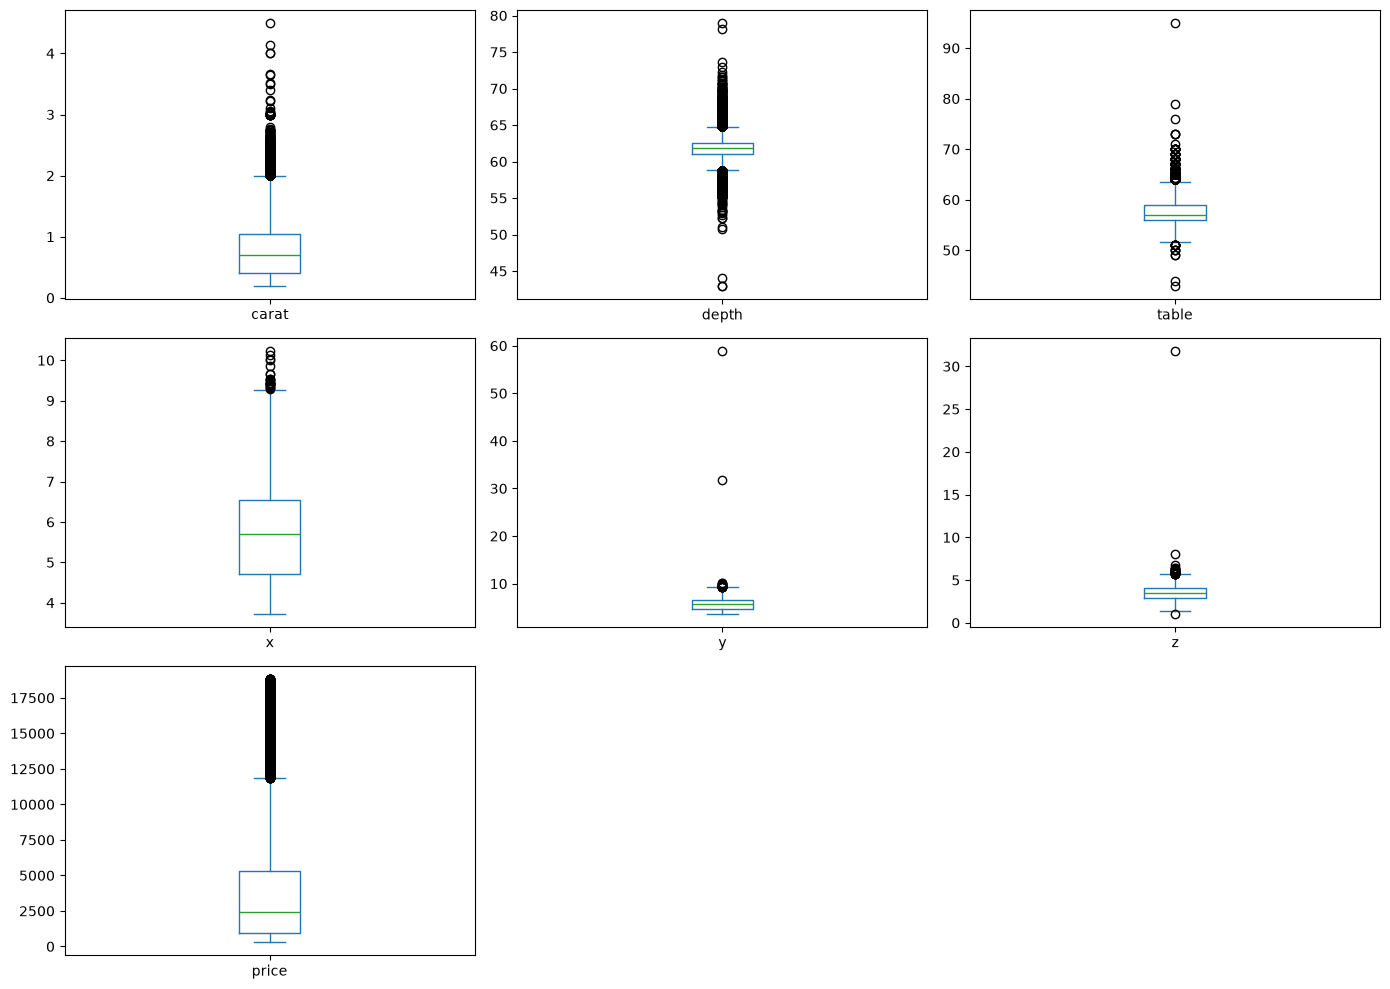

In [10]:
diamonds_df[num_cols].plot.box(subplots=True, layout=(3, 3), figsize=(14, 10))
plt.tight_layout()
plt.show()

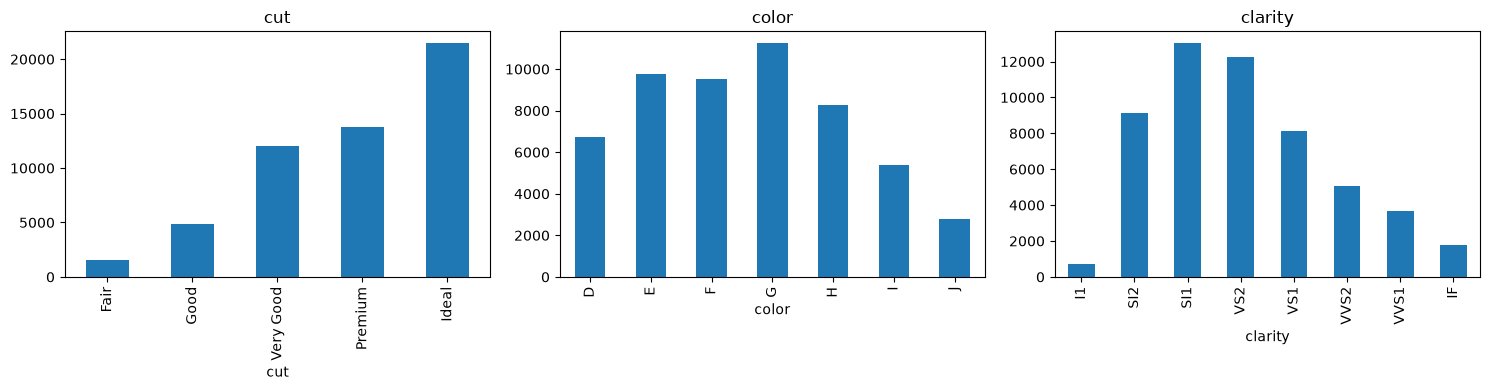

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_cols):
    diamonds_df[col].value_counts().reindex(orders[col]).plot.bar(ax=ax, title=col)
plt.tight_layout()
plt.show()

**Respuesta 2**

Las variables numéricas `carat` y `price` tienen sesgo a la derecha (la media es mayor que la mediana: 0.80 vs. 0.70 quilates y 3,930 vs. 2,401 dólares) y muestran muchos valores atípicos altos en los boxplots. `depth` y `table` se concentran alrededor de 61.8 y 57, con atípicos en ambos extremos. En `y` y `z` hay valores muy alejados del resto (máximos de 58.9 y 31.8 mm), que parecen errores de captura. Entre las categóricas, los cortes más frecuentes son `Ideal` (21,485) y `Premium`, el color más común es `G` (11,254) y la claridad más común es `SI1` (13,030). Las categorías menos frecuentes son `Fair`, `J` e `I1`.

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

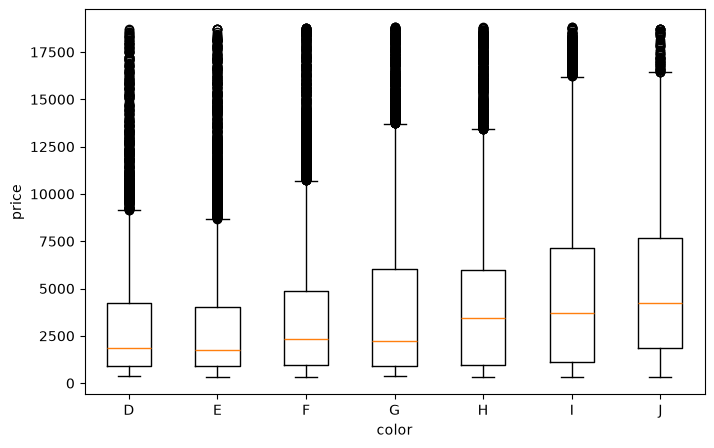

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([diamonds_df.loc[diamonds_df["color"] == c, "price"] for c in color_order], tick_labels=color_order)
ax.set_xlabel("color")
ax.set_ylabel("price")
plt.show()

In [13]:
diamonds_df.groupby("color")[["carat", "price"]].median().reindex(color_order)

,carat,price
color,,
D,0.53,1842.0
E,0.53,1741.5
F,0.70,2345.0
G,0.70,2242.0
H,0.90,3447.0
I,1.00,3719.0
J,1.11,4234.0


**Respuesta 3 (color)**

No, la tendencia no es la esperada: como `D` es el mejor color, se esperaría que sus diamantes fueran los más caros, pero la mediana del precio sube de 1,842 en `D` a 4,234 en `J`. Una variable que influye es `carat`: la mediana del peso crece de 0.53 quilates en `D` a 1.11 en `J`, es decir, los diamantes de peor color de esta muestra son más pesados y, como el peso eleva mucho el precio, compensan el efecto del color.

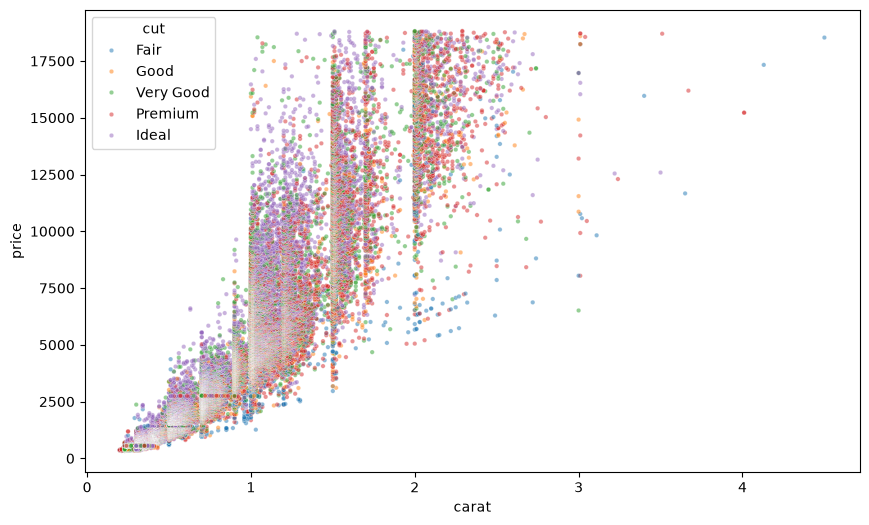

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=diamonds_df, x="carat", y="price", hue="cut", hue_order=cut_order, s=10, alpha=0.5)
plt.show()

**Respuesta 3 (corte)**

El precio crece con el peso del diamante de forma no lineal (más rápido a partir de 1 quilate) y la dispersión del precio aumenta con el peso. Para un mismo peso, los cortes de mejor calidad (`Ideal`) tienden a ubicarse en la parte alta de la nube y los `Fair` en la parte baja, pero hay mucho traslape, por lo que el peso explica el precio mucho más que el corte.

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

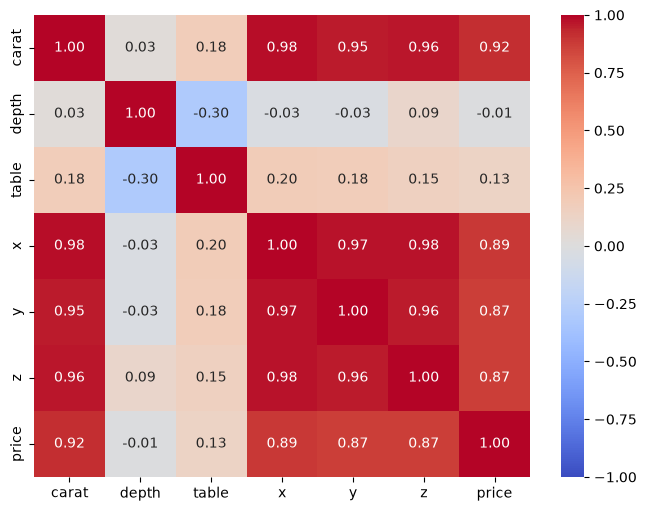

In [15]:
corr = diamonds_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

In [16]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.9])

carat  x        0.978108
       y        0.954222
       z        0.961213
       price    0.921846
x      y        0.974799
       z        0.975361
y      z        0.956587
dtype: float64


**Respuesta 4 (pares con correlación > 0.9)**

Además de `carat` con `price` (0.92), las correlaciones superiores a 0.9 se dan entre `carat`, `x`, `y` y `z`: los cuatro están correlacionados entre sí (0.95 a 0.98). `carat` captura la información de `x`, `y` y `z`, ya que el peso depende del tamaño del diamante, y es el que tiene mayor correlación con `price` (0.92 frente a 0.89, 0.87 y 0.87). Por eso se conserva `carat` y se eliminan `x`, `y` y `z`. La correlación entre `carat` y `price` no se trata como redundancia porque `price` es la variable objetivo.

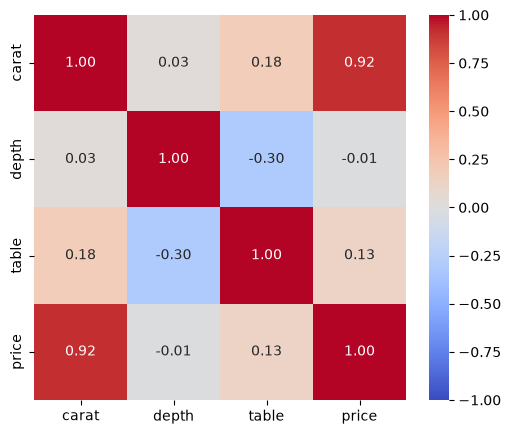

In [17]:
diamonds_df = diamonds_df.drop(columns=["x", "y", "z"])
corr = diamonds_df.corr(numeric_only=True)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

**Respuesta 4 (verificación)**

Con `carat`, `depth` y `table` como predictores, la mayor correlación entre ellos es -0.30 (`depth` y `table`), por lo que ya no quedan predictores altamente correlacionados.

5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [18]:
best_corr = corr["price"].drop("price").abs().idxmax()

X = diamonds_df[[best_corr]]
y = diamonds_df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

lin_reg = LinearRegression().fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

results = pd.DataFrame([["Baseline", root_mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)]],
                       columns=["Modelo", "RMSE", "R2"])
print(f"price = {lin_reg.intercept_:.2f} + {lin_reg.coef_[0]:.2f} × {best_corr}")
results

price = -2276.79 + 7792.73 × carat


,Modelo,RMSE,R2
0,Baseline,1532.43849,0.84618


**Respuesta 5**

El predictor más correlacionado con `price` es `carat`. El modelo obtuvo un RMSE de 1,532.44 dólares y un R² de 0.846 en el conjunto de prueba. Según la ecuación, cada quilate adicional aumenta el precio en promedio 7,792.73 dólares, y el modelo explica cerca del 85% de la variabilidad del precio.

6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [19]:
X = diamonds_df.drop(columns="price")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

preprocessing = ColumnTransformer([
    ("num", RobustScaler(), make_column_selector(dtype_include="number")),
    ("cat", OrdinalEncoder(categories=[cut_order, color_order, clarity_order]),
     make_column_selector(dtype_exclude="number")),
], verbose_feature_names_out=False)

ordinal_robust = make_pipeline(preprocessing, LinearRegression()).fit(X_train, y_train)
y_pred = ordinal_robust.predict(X_test)

results.loc[len(results)] = ["Ordinal_Robust", root_mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)]
results

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016


**Respuesta 6**

Para la codificación ordinal se usó el orden de la descripción de las variables: `cut` de `Fair` a `Ideal`, `color` de `D` a `J` y `clarity` de `I1` a `IF`. Con todos los predictores el modelo mejora al baseline: el RMSE baja de 1,532.44 a 1,216.82 y el R² sube de 0.846 a 0.903.

7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [20]:
preprocessing2 = ColumnTransformer([
    ("num", MinMaxScaler(), make_column_selector(dtype_include="number")),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), make_column_selector(dtype_exclude="number")),
], verbose_feature_names_out=False)

ohe_minmax = make_pipeline(preprocessing2, LinearRegression()).fit(X_train, y_train)
y_pred = ohe_minmax.predict(X_test)

results.loc[len(results)] = ["OHE_MinMax", root_mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)]
results

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499


**Respuesta 7**

El modelo mejora un poco más: RMSE de 1,142.52 y R² de 0.914. El escalamiento no cambia las predicciones de una regresión lineal, así que la mejora viene de la codificación one-hot, que asigna un coeficiente propio a cada categoría en lugar de suponer que los pasos entre categorías consecutivas son iguales, como hace la codificación ordinal.

8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [21]:
poly_degree2 = make_pipeline(preprocessing2, PolynomialFeatures(degree=2, include_bias=False),
                             LinearRegression()).fit(X_train, y_train)
y_pred_poly = poly_degree2.predict(X_test)

results.loc[len(results)] = ["PolynomialDegree2", root_mean_squared_error(y_test, y_pred_poly),
                             r2_score(y_test, y_pred_poly)]
results

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499
3,PolynomialDegree2,748.838380,0.963270


**Respuesta 8**

Sí mejora el ajuste: el RMSE baja a 748.84 y el R² sube a 0.963, el mejor resultado hasta ahora. El modelo polinomial captura la relación no lineal entre el peso y el precio, así como interacciones entre variables, a costa de pasar de 20 a 230 columnas.

9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

In [22]:
results = results.sort_values("R2", ascending=False).reset_index(drop=True)
results

,Modelo,RMSE,R2
0,PolynomialDegree2,748.838380,0.963270
1,OHE_MinMax,1142.519131,0.914499
2,Ordinal_Robust,1216.822219,0.903016
3,Baseline,1532.438490,0.846180


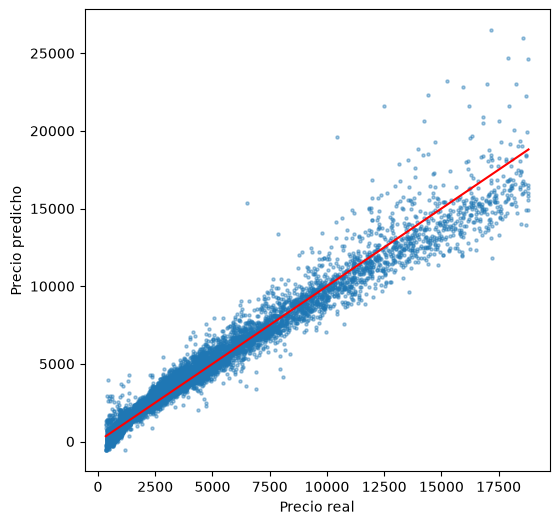

In [23]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_poly, s=5, alpha=0.4)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="red")
plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.show()

**Respuesta 9**

El mejor modelo es `PolynomialDegree2`. En el gráfico, los puntos se concentran cerca de la diagonal, sobre todo en precios bajos y medios. La dispersión crece en los precios altos, donde varios diamantes de más de 12,500 dólares quedan subestimados, y algunas predicciones de diamantes baratos resultan negativas.

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [24]:
poly_degree2

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['carat','cut','color','clarity','depth','table']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names a

In [25]:
feature_names = poly_degree2[0].get_feature_names_out()
print(feature_names)

['carat' 'depth' 'table' 'cut_Good' 'cut_Ideal' 'cut_Premium'
 'cut_Very Good' 'color_E' 'color_F' 'color_G' 'color_H' 'color_I'
 'color_J' 'clarity_IF' 'clarity_SI1' 'clarity_SI2' 'clarity_VS1'
 'clarity_VS2' 'clarity_VVS1' 'clarity_VVS2']


In [26]:
poly_names = poly_degree2[1].get_feature_names_out(feature_names)
print(len(poly_names), "columnas polinómicas")
print(poly_names)

230 columnas polinómicas
['carat' 'depth' 'table' 'cut_Good' 'cut_Ideal' 'cut_Premium'
 'cut_Very Good' 'color_E' 'color_F' 'color_G' 'color_H' 'color_I'
 'color_J' 'clarity_IF' 'clarity_SI1' 'clarity_SI2' 'clarity_VS1'
 'clarity_VS2' 'clarity_VVS1' 'clarity_VVS2' 'carat^2' 'carat depth'
 'carat table' 'carat cut_Good' 'carat cut_Ideal' 'carat cut_Premium'
 'carat cut_Very Good' 'carat color_E' 'carat color_F' 'carat color_G'
 'carat color_H' 'carat color_I' 'carat color_J' 'carat clarity_IF'
 'carat clarity_SI1' 'carat clarity_SI2' 'carat clarity_VS1'
 'carat clarity_VS2' 'carat clarity_VVS1' 'carat clarity_VVS2' 'depth^2'
 'depth table' 'depth cut_Good' 'depth cut_Ideal' 'depth cut_Premium'
 'depth cut_Very Good' 'depth color_E' 'depth color_F' 'depth color_G'
 'depth color_H' 'depth color_I' 'depth color_J' 'depth clarity_IF'
 'depth clarity_SI1' 'depth clarity_SI2' 'depth clarity_VS1'
 'depth clarity_VS2' 'depth clarity_VVS1' 'depth clarity_VVS2' 'table^2'
 'table cut_Good' 'table 

In [27]:
lin_model = poly_degree2[-1]
print("Intercepto:", lin_model.intercept_)

coefs = pd.Series(lin_model.coef_, index=poly_names)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

Intercepto: -1619.562838155302


carat^2               55138.497649
carat clarity_IF      49898.316662
carat clarity_VVS1    46662.337832
carat clarity_VVS2    44769.175537
carat clarity_VS1     40020.571581
carat clarity_VS2     37083.049534
carat clarity_SI1     31988.729725
carat clarity_SI2     24361.063098
carat color_J        -20652.315075
carat color_I        -14269.632273
dtype: float64

**Respuesta 10**

Después del preprocesamiento hay 20 columnas (3 numéricas y 17 dummies) y, tras la transformación polinomial, 230. Los 10 coeficientes más grandes en valor absoluto, que están sobre predictores escalados entre 0 y 1 y por lo tanto son comparables entre sí, corresponden todos a `carat`:

* `carat^2` es el mayor y es positivo, así que el precio crece cada vez más rápido con el peso.
* Las interacciones de `carat` con la claridad son positivas y siguen el orden de la claridad (`IF`, `VVS1`, `VVS2`, `VS1`, `VS2`, `SI1`, `SI2`, de mayor a menor): a mayor claridad, cada quilate vale más (la categoría de referencia es `I1`).
* Las interacciones de `carat` con los colores `J` e `I` son negativas, lo que indica que un color peor reduce el valor de cada quilate respecto al color `D`.

En conclusión, el peso es el factor que más influye en el precio y la claridad y el color modulan cuánto vale cada quilate; `cut`, `depth` y `table` no aparecen entre los 10 más importantes. Como hay interacciones y términos al cuadrado, los coeficientes no miden el efecto aislado de cada variable y deben interpretarse en conjunto.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude Code (basado en Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis. https://claude.com/claude-code

---